# بخش سوم — رنگی‌سازی تصاویر (Autoencoder)

مدل از پیش آموزش‌دیده کانال **L** فضای **Lab** را می‌گیرد و کانال‌های **a** و **b** را پیش‌بینی می‌کند.

**نیازمندی‌ها:** `tensorflow`, `opencv-python`, `matplotlib`, `numpy`, `scikit-image`

**Google Colab:** پوشه `Colorized-Img` را در Google Drive بگذارید، سلول «اتصال به Drive» را اجرا کنید، مسیر `DRIVE_FOLDER` را تنظیم کنید.

## اتصال به Google Drive

1. پوشه `Colorized-Img` را در Drive آپلود کنید (شامل تصاویر + زیرپوشه `Colorized-Img/colorize_autoencoder_first1000.keras`).
2. سلول زیر را اجرا کنید و اجازه دسترسی بدهید.
3. در سلول بعدی مسیر `DRIVE_FOLDER` را مطابق محل پوشه در Drive تنظیم کنید.

**مهم:** فایل `.keras` باینری است — فقط با `tf.keras.models.load_model()` بارگذاری شود (نه `pd.read_csv`).

In [1]:
try:
    from google.colab import drive

    drive.mount("/content/drive")
    print("Google Drive mounted at /content/drive/MyDrive")
except ImportError:
    print("Not in Colab — skip Drive mount (use local Colorized-Img folder).")

# Uncomment if load_model fails with a Keras version error:
# !pip install -q -U "keras>=3.8" "tensorflow>=2.16"

Mounted at /content/drive
Google Drive mounted at /content/drive/MyDrive


In [2]:
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf
from skimage.color import lab2rgb, rgb2lab

MODEL_NAME = "colorize_autoencoder_first1000.keras"
IMAGE_NAMES = [
    "forest.397.jpg",
    "forest.399.jpg",
    "YIN8QU2CC97X.jpg",
    "ZYLOMHW6DWLE.jpg",
]


def find_file(filename, roots):
    """Search common folders (local notebook dir, Colab /content, Drive)."""
    for root in roots:
        root = Path(root)
        if not root.exists():
            continue
        direct = root / filename
        if direct.is_file():
            return direct.resolve()
        try:
            match = next(root.rglob(filename))
            return match.resolve()
        except StopIteration:
            continue
    return None


# ===== Edit this path: folder "Colorized-Img" inside your Google Drive =====
DRIVE_FOLDER = Path("/content/drive/MyDrive/Colorized-Img")

SEARCH_ROOTS = []
if DRIVE_FOLDER.exists():
    SEARCH_ROOTS.append(DRIVE_FOLDER)
else:
    print(f"Warning: DRIVE_FOLDER not found: {DRIVE_FOLDER}")
    print("Examples: /content/drive/MyDrive/CA3/Colorized-Img")
    print("          /content/drive/MyDrive/Colab Notebooks/Colorized-Img")

# Fallbacks: search all Drive, then /content and current folder
if Path("/content/drive/MyDrive").exists():
    SEARCH_ROOTS.append(Path("/content/drive/MyDrive"))
SEARCH_ROOTS.extend([Path("/content"), Path.cwd()])

MODEL_PATH = find_file(MODEL_NAME, SEARCH_ROOTS)
if MODEL_PATH is None:
    raise FileNotFoundError(
        f"Model not found: {MODEL_NAME}\n"
        f"DRIVE_FOLDER = {DRIVE_FOLDER}\n"
        "Put Colorized-Img on Drive, set DRIVE_FOLDER, run the Drive mount cell, then re-run.\n"
        f"MyDrive top-level: {list(Path('/content/drive/MyDrive').iterdir())[:15]}"
    )

# Images live in Colorized-Img/; model is in Colorized-Img/Colorized-Img/
if (MODEL_PATH.parent.parent / IMAGE_NAMES[0]).exists():
    BASE = MODEL_PATH.parent.parent
elif (MODEL_PATH.parent / IMAGE_NAMES[0]).exists():
    BASE = MODEL_PATH.parent
else:
    BASE = find_file(IMAGE_NAMES[0], SEARCH_ROOTS)
    if BASE is None:
        raise FileNotFoundError(
            f"Model found at {MODEL_PATH}, but test images were not found.\n"
            "Upload forest.397.jpg (and other images) into the same folder as the model "
            "or into a parent Colorized-Img folder."
        )
    BASE = BASE.parent

IMAGE_PATHS = [BASE / name for name in IMAGE_NAMES]
missing = [p for p in IMAGE_PATHS if not p.is_file()]
if missing:
    raise FileNotFoundError(f"Missing images:\n" + "\n".join(f"  - {p}" for p in missing))

print("MODEL_PATH:", MODEL_PATH)
print("BASE (images):", BASE)
print("Model exists:", MODEL_PATH.is_file(), "| size (MB):", MODEL_PATH.stat().st_size / 1e6)

MODEL_PATH: /content/drive/MyDrive/Colorized-Img/Colorized-Img/colorize_autoencoder_first1000.keras
BASE (images): /content/drive/MyDrive/Colorized-Img
Model exists: True | size (MB): 37.347863


## گام ۱ — بارگذاری مدل و مشاهده معماری

In [3]:
if not MODEL_PATH.is_file():
    raise FileNotFoundError(f"Model file missing: {MODEL_PATH}")

import zipfile

size_mb = MODEL_PATH.stat().st_size / (1024 * 1024)
print(f"File: {MODEL_PATH}")
print(f"Size: {size_mb:.1f} MB (expected ~35-37 MB)")

if size_mb < 30:
    raise ValueError("Model file too small — re-upload the full .keras file (~37 MB).")
if not zipfile.is_zipfile(MODEL_PATH):
    raise ValueError(
        "Not a valid .keras zip. Never use pd.read_csv() on this file. "
        "Re-upload colorize_autoencoder_first1000.keras."
    )

# Load binary Keras model (correct method)
model = tf.keras.models.load_model(str(MODEL_PATH), compile=False)
model.summary()

File: /content/drive/MyDrive/Colorized-Img/Colorized-Img/colorize_autoencoder_first1000.keras
Size: 35.6 MB (expected ~35-37 MB)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 256, 256, 64)   │           640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 256, 256, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 128, 128, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 128, 128, 128)  │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 128, 128, 128)  │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 64, 64, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 64, 64, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 64, 64, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 32, 32, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 32, 32, 512)    │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 32, 32, 512)    │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 32, 32, 256)    │     1,179,904 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 32, 32, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d (UpSampling2D)    │ (None, 64, 64, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 64, 64, 128)    │       295,040 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 64, 64, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d_1 (UpSampling2D)  │ (None, 128, 128, 128)  │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 128, 128, 64)   │        73,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 128, 128, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d_2 (UpSampling2D)  │ (None, 256, 256, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 256, 256, 2)    │         1,154 │
└─────────────────────────────────┴────────────────────────┴─────────────

 Total params: 3,105,346 (11.85 MB)

 Trainable params: 3,102,530 (11.84 MB)

 Non-trainable params: 2,816 (11.00 KB)

## گام ۲ — پیش‌پردازش (دو روش استخراج کانال L)

1. تصویر را خاکستری می‌کنیم.
2. **روش اول:** تکرار سه‌باره کانال خاکستری → `rgb2lab` → استخراج L.
3. **روش دوم:** خواندن با `cv2.IMREAD_COLOR` → `rgb2lab` → استخراج L.
4. تغییر اندازه به `256×256` و آماده‌سازی ورودی با شکل `(1, 256, 256, 1)` و مقادیر L در بازه ۰ تا ۱۰۰.

In [4]:
IMG_SIZE = 256


def read_bgr(path):
    img = cv2.imread(str(path))
    if img is None:
        raise FileNotFoundError(path)
    return img


def to_grayscale(bgr):
    return cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY)


def extract_L_method1(gray):
    """Stack gray 3 times -> pseudo RGB -> Lab -> L."""
    rgb = np.stack([gray, gray, gray], axis=-1)
    lab = rgb2lab(rgb)
    return lab[:, :, 0]


def extract_L_method2(gray):
    """Gray -> 3-channel BGR (like IMREAD_COLOR) -> Lab -> L."""
    bgr = cv2.cvtColor(gray, cv2.COLOR_GRAY2BGR)
    rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
    lab = rgb2lab(rgb)
    return lab[:, :, 0]


def prepare_L_channel(L, size=IMG_SIZE):
    L = cv2.resize(L, (size, size), interpolation=cv2.INTER_AREA)
    L = np.clip(L, 0, 100).astype(np.float32)
    return L.reshape(1, size, size, 1)


def rotate_image(img, angle):
    h, w = img.shape[:2]
    center = (w / 2, h / 2)
    M = cv2.getRotationMatrix2D(center, angle, 1.0)
    return cv2.warpAffine(
        img, M, (w, h), flags=cv2.INTER_LINEAR, borderMode=cv2.BORDER_REFLECT
    )


def prepare_L_method1(gray, noise_std=None, brightness=1.0):
    """Method 1: extract L, optional noise before resize/clip, brightness scale."""
    L = extract_L_method1(gray)
    if noise_std is not None:
        L = L + np.random.normal(0, noise_std, L.shape)
    L = cv2.resize(L, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_AREA)
    if brightness != 1.0:
        L = L * brightness
    L = np.clip(L, 0, 100).astype(np.float32)
    return L.reshape(1, IMG_SIZE, IMG_SIZE, 1)


def rotate_rgb_float(rgb, angle):
    u8 = (np.clip(rgb, 0, 1) * 255).astype(np.uint8)
    return rotate_image(u8, angle).astype(np.float32) / 255.0

### نمایش ۴ تصویر — هر دو روش (کانال L با ابعاد 256×256×1)

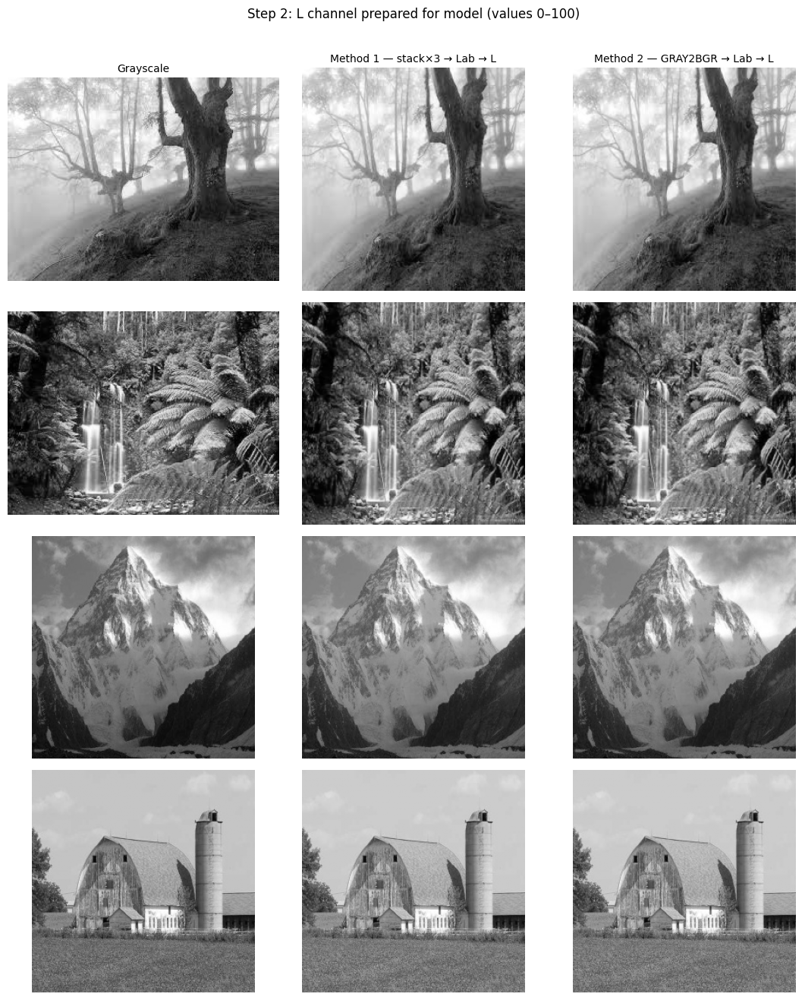

Shapes (batch, H, W, C) — must be (1, 256, 256, 1):
  forest.397.jpg:  method1 (1, 256, 256, 1)  |  method2 (1, 256, 256, 1)
  forest.399.jpg:  method1 (1, 256, 256, 1)  |  method2 (1, 256, 256, 1)
  YIN8QU2CC97X.jpg:  method1 (1, 256, 256, 1)  |  method2 (1, 256, 256, 1)
  ZYLOMHW6DWLE.jpg:  method1 (1, 256, 256, 1)  |  method2 (1, 256, 256, 1)


In [5]:
fig, axes = plt.subplots(4, 3, figsize=(11, 13))
col_titles = ["Grayscale", "Method 1 — stack×3 → Lab → L", "Method 2 — GRAY2BGR → Lab → L"]

for row, path in enumerate(IMAGE_PATHS):
    bgr = read_bgr(path)
    gray = to_grayscale(bgr)

    L1_batch = prepare_L_channel(extract_L_method1(gray))
    L2_batch = prepare_L_channel(extract_L_method2(gray))
    L1 = L1_batch[0, :, :, 0]
    L2 = L2_batch[0, :, :, 0]

    axes[row, 0].imshow(gray, cmap="gray")
    axes[row, 1].imshow(L1, cmap="gray", vmin=0, vmax=100)
    axes[row, 2].imshow(L2, cmap="gray", vmin=0, vmax=100)

    axes[row, 0].set_ylabel(path.name, fontsize=9)
    if row == 0:
        for col, title in enumerate(col_titles):
            axes[row, col].set_title(title, fontsize=10)
    for col in range(3):
        axes[row, col].axis("off")

plt.suptitle("Step 2: L channel prepared for model (values 0–100)", fontsize=12, y=1.01)
plt.tight_layout()
plt.show()

print("Shapes (batch, H, W, C) — must be (1, 256, 256, 1):")
for path in IMAGE_PATHS:
    gray = to_grayscale(read_bgr(path))
    s1 = prepare_L_channel(extract_L_method1(gray)).shape
    s2 = prepare_L_channel(extract_L_method2(gray)).shape
    print(f"  {path.name}:  method1 {s1}  |  method2 {s2}")

## گام ۳ — اجرای مدل و نمایش تصویر رنگی

خروجی a و b در بازه `[-1, 1]` (tanh) است؛ برای `lab2rgb` آن‌ها را در ۱۱۰ ضرب می‌کنیم.

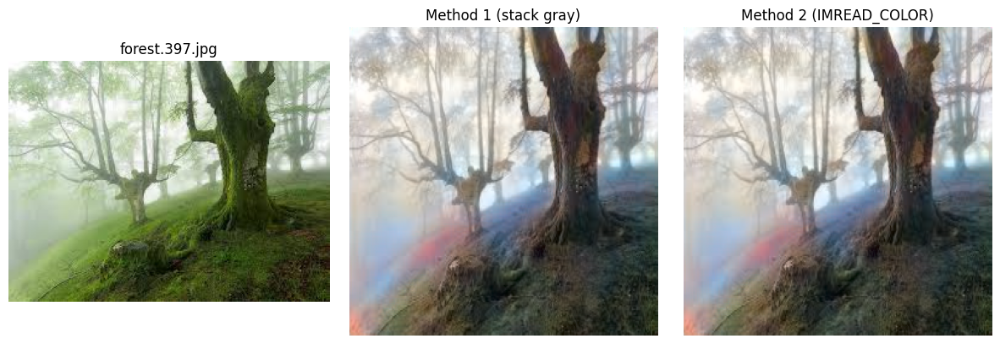

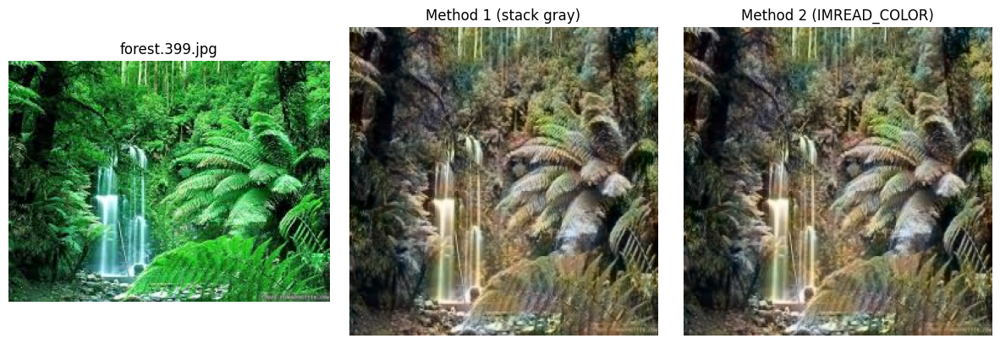

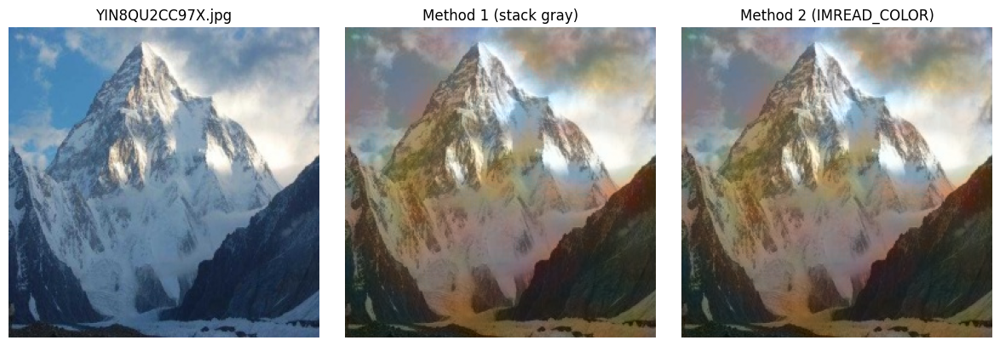

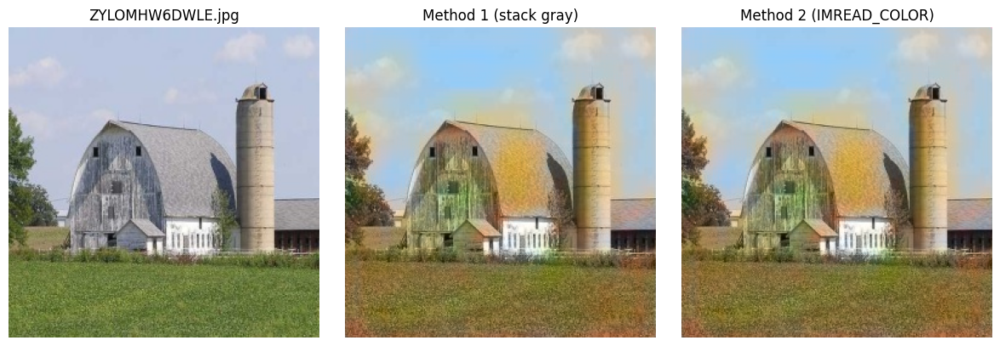

In [6]:
def colorize(L_batch):
    ab = model.predict(L_batch, verbose=0)
    L = L_batch[0, :, :, 0]
    a = ab[0, :, :, 0] * 110.0
    b = ab[0, :, :, 1] * 110.0
    lab = np.stack([L, a, b], axis=-1)
    rgb = lab2rgb(lab)
    return np.clip(rgb, 0, 1)


def show_pair(original_bgr, color_rgb, title):
    fig, axes = plt.subplots(1, 2, figsize=(10, 4))
    axes[0].imshow(cv2.cvtColor(original_bgr, cv2.COLOR_BGR2RGB))
    axes[0].set_title("Original")
    axes[0].axis("off")
    axes[1].imshow(color_rgb)
    axes[1].set_title(title)
    axes[1].axis("off")
    plt.tight_layout()
    plt.show()


for path in IMAGE_PATHS:
    bgr = read_bgr(path)
    gray = to_grayscale(bgr)

    L1 = prepare_L_channel(extract_L_method1(gray))
    L2 = prepare_L_channel(extract_L_method2(gray))

    out1 = colorize(L1)
    out2 = colorize(L2)

    fig, axes = plt.subplots(1, 3, figsize=(12, 4))
    axes[0].imshow(cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB))
    axes[0].set_title(path.name)
    axes[0].axis("off")
    axes[1].imshow(out1)
    axes[1].set_title("Method 1 (stack gray)")
    axes[1].axis("off")
    axes[2].imshow(out2)
    axes[2].set_title("Method 2 (IMREAD_COLOR)")
    axes[2].axis("off")
    plt.tight_layout()
    plt.show()

## گام ۴ — آزمایش پایداری (فقط روش اول)

طبق دستورالعمل تمرین، همه آزمایش‌های زیر فقط با **روش اول** (تکرار سه‌باره کانال خاکستری) انجام می‌شوند.

### الف) چرخش ۴۵ درجه

تصویر خاکستری ۴۵° می‌چرخد → استخراج L → رنگی‌سازی → چرخش خروجی **۴۵°-** برای هم‌راستا شدن با حالت بدون چرخش.

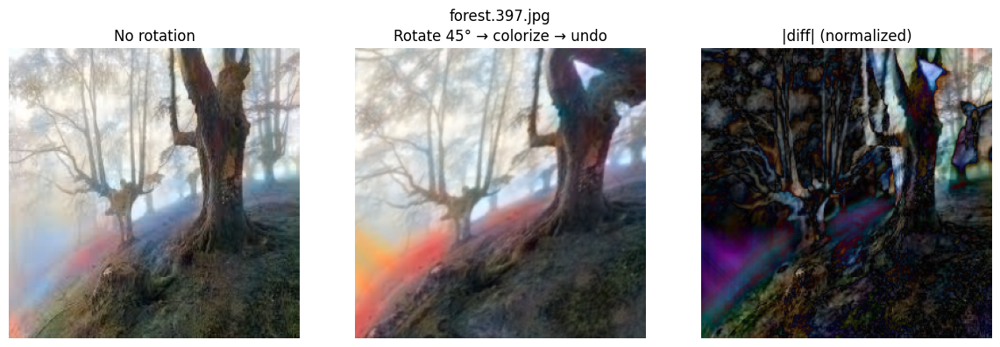

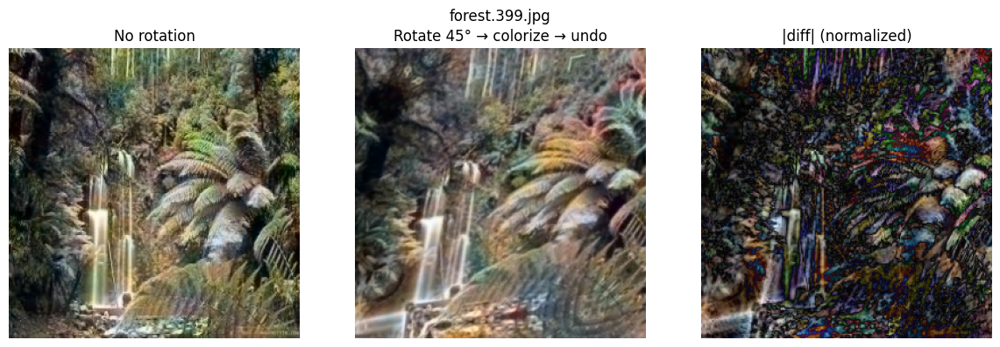

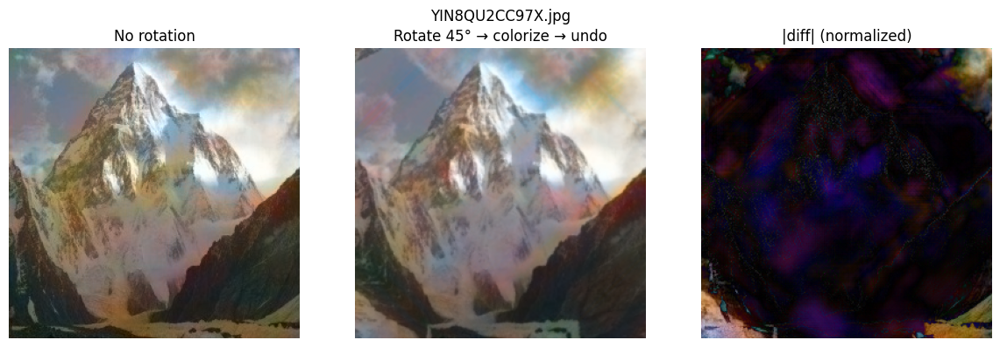

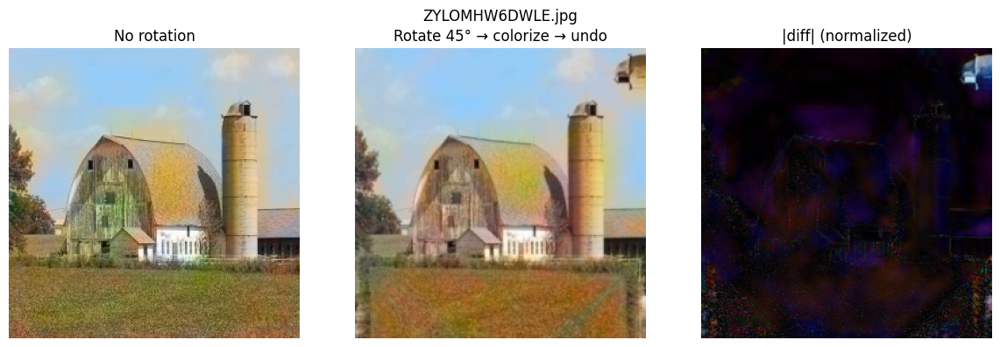

In [7]:
ROT_ANGLE = 45

for path in IMAGE_PATHS:
    gray = to_grayscale(read_bgr(path))

    L_base = prepare_L_method1(gray)
    out_base = colorize(L_base)

    gray_rot = rotate_image(gray, ROT_ANGLE)
    L_rot = prepare_L_method1(gray_rot)
    out_rot_aligned = rotate_rgb_float(colorize(L_rot), -ROT_ANGLE)

    fig, axes = plt.subplots(1, 3, figsize=(12, 4))
    axes[0].imshow(out_base)
    axes[0].set_title("No rotation")
    axes[0].axis("off")
    axes[1].imshow(out_rot_aligned)
    axes[1].set_title("Rotate 45° → colorize → undo")
    axes[1].axis("off")
    diff = np.abs(out_base - out_rot_aligned)
    axes[2].imshow(diff / (diff.max() + 1e-8))
    axes[2].set_title("|diff| (normalized)")
    axes[2].axis("off")
    fig.suptitle(path.name)
    plt.tight_layout()
    plt.show()

**تحلیل چرخش:** مدل روی تصاویر ۲۵۶×۲۵۶ و بدون آموزش روی چرخش طراحی نشده است. پس از چرخش، حاشیه‌های خالی و الگوهای مورب باعث می‌شود رنگ‌ها کدر یا نامتعادل شوند؛ پس از برگرداندن خروجی، اغلب در لبه‌ها و جزئیات ریز اختلاف بیشتری دیده می‌شود. در نواحی یکنواخت (آسمان، دیوار) تفاوت کمتر و در بافت‌های پیچیده (برگ، ساختمان) بیشتر است.

### ب) نویز گوسی روی کانال L

نویز با انحراف معیار **۰.۱** بعد از استخراج L و **قبل** از resize و clip به [0, 100] اضافه می‌شود.

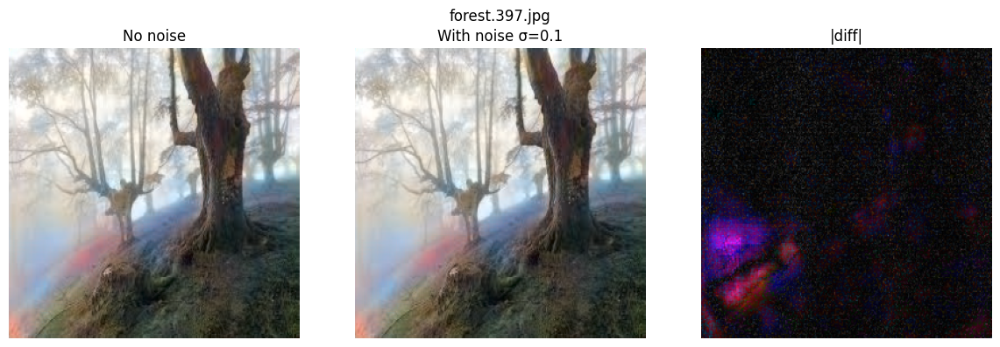

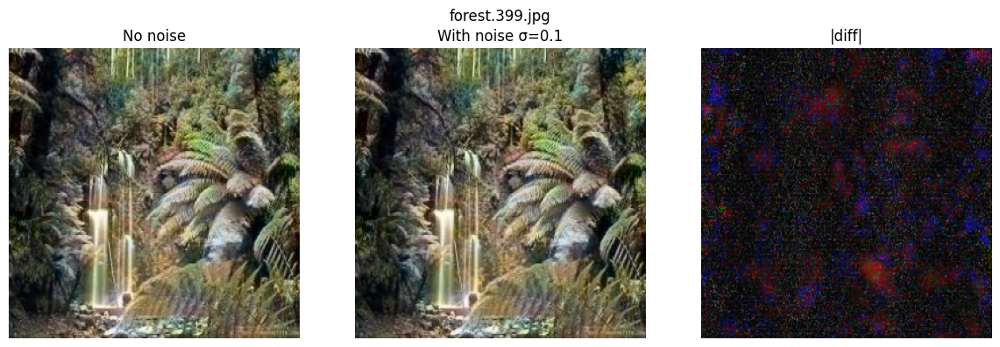

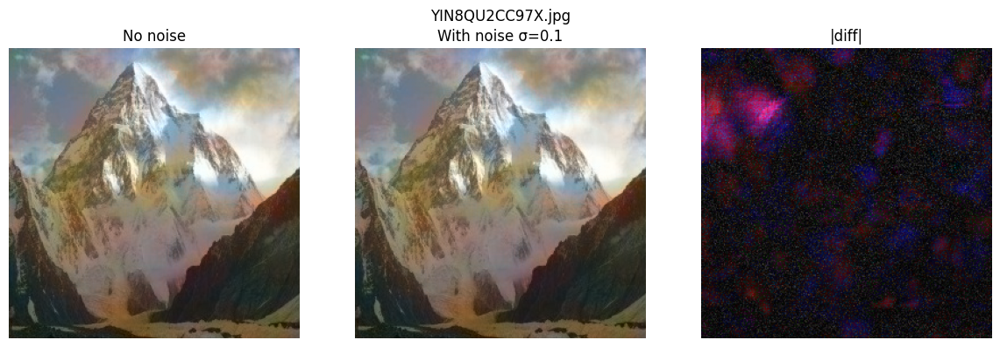

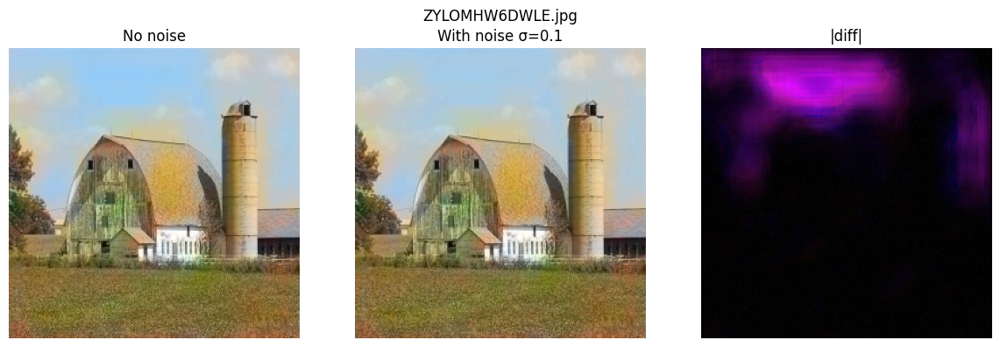

In [8]:
np.random.seed(42)
NOISE_STD = 0.1

for path in IMAGE_PATHS:
    gray = to_grayscale(read_bgr(path))

    L_clean = prepare_L_method1(gray)
    L_noisy = prepare_L_method1(gray, noise_std=NOISE_STD)

    out_clean = colorize(L_clean)
    out_noisy = colorize(L_noisy)

    fig, axes = plt.subplots(1, 3, figsize=(12, 4))
    axes[0].imshow(out_clean)
    axes[0].set_title("No noise")
    axes[0].axis("off")
    axes[1].imshow(out_noisy)
    axes[1].set_title(f"With noise σ={NOISE_STD}")
    axes[1].axis("off")
    diff = np.abs(out_clean - out_noisy)
    axes[2].imshow(diff / (diff.max() + 1e-8))
    axes[2].set_title("|diff|")
    axes[2].axis("off")
    fig.suptitle(path.name)
    plt.tight_layout()
    plt.show()

**تحلیل نویز:** نویز روی L مستقیماً روشنایی را مختل می‌کند؛ مدل ab را از L تخمین می‌زند، بنابراین **نواحی با گرادیان شدید** (لبه درخت، خطوط ساختمان، مرز آسمان) و **بافت‌های ریز** بیشتر رنگ‌پریدگی و لکه‌لکه شدن نشان می‌دهند. نواحی صاف و یکدست معمولاً پایدارتر می‌مانند.

### ج) تغییر روشنایی کانال L

کانال L پس از resize در **۰.۷** (تاریک‌تر) و **۱.۳** (روشن‌تر) ضرب شده و به مدل داده می‌شود.

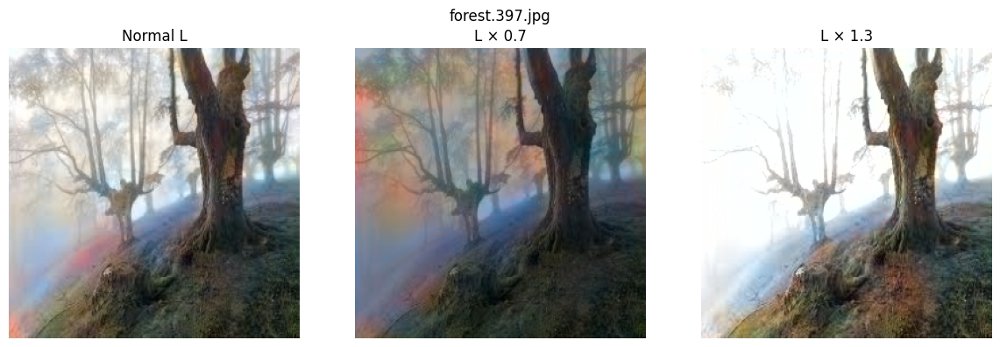

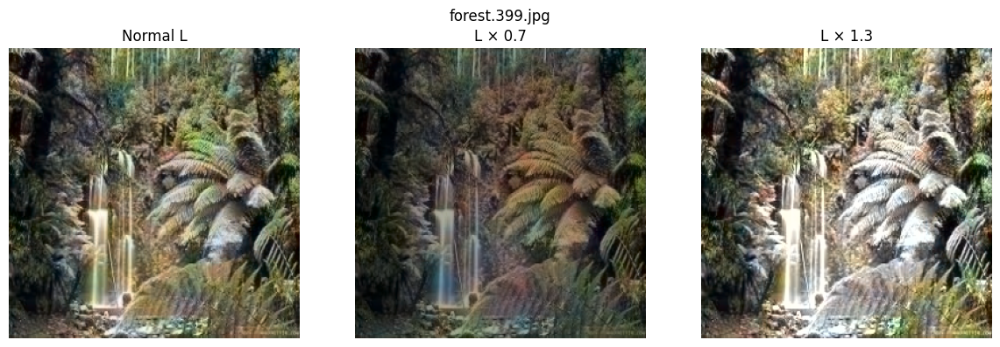

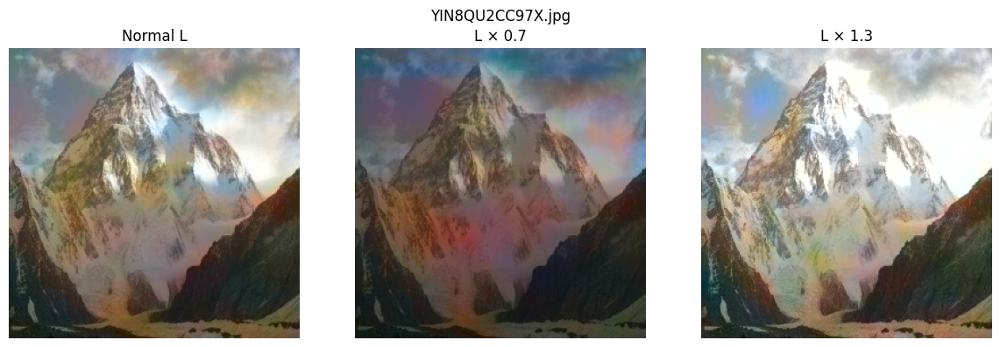

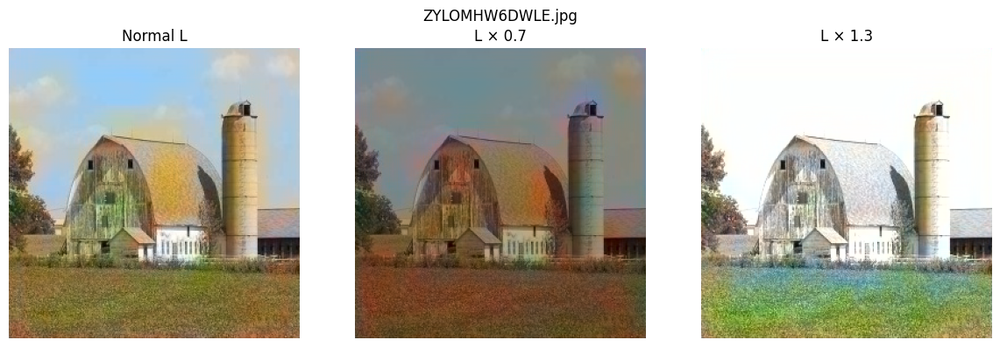

In [9]:
for path in IMAGE_PATHS:
    gray = to_grayscale(read_bgr(path))

    out_normal = colorize(prepare_L_method1(gray))
    out_dark = colorize(prepare_L_method1(gray, brightness=0.7))
    out_bright = colorize(prepare_L_method1(gray, brightness=1.3))

    fig, axes = plt.subplots(1, 3, figsize=(12, 4))
    axes[0].imshow(out_normal)
    axes[0].set_title("Normal L")
    axes[0].axis("off")
    axes[1].imshow(out_dark)
    axes[1].set_title("L × 0.7")
    axes[1].axis("off")
    axes[2].imshow(out_bright)
    axes[2].set_title("L × 1.3")
    axes[2].axis("off")
    fig.suptitle(path.name)
    plt.tight_layout()
    plt.show()

**تحلیل روشنایی:** با کم کردن L، کل تصویر تیره‌تر می‌شود اما **رنگ‌های ab** اغلب تقریباً مشابه حالت عادی می‌مانند (مدل رنگ را عمدتاً از بافت L استنباط می‌کند، نه فقط از شدت روشنایی). با L×1.3 و clip به ۱۰۰، نواحی روشن ممکن است **اشباع و کم‌رنگ** شوند چون جزئیات روشنایی از دست می‌رود؛ رنگ‌ها همیشه متناسب با روشنایی واقعی نیستند.

---

## تحلیل گام ۳ — مقایسه روش اول و دوم

- **روش اول (stack gray):** مستقیماً از ماتریس خاکستری ساخته می‌شود؛ برای تصاویر واقعاً تک‌کاناله پایدارتر است.
- **روش دوم (GRAY2BGR):** معمولاً خروجی مشابه روش اول دارد، چون هر دو در عمل یک RGB با سه کانال برابر می‌سازند.
- اگر تفاوتی دیده شود، اغلب به **ترتیب کانال‌ها** یا **نوع داده** (uint8 در OpenCV در برابر stack در NumPy) برمی‌گردد؛ در عمل برای این تمرین **روش اول** برای آزمایش‌های پایداری توصیه شده و کافی است.